<a href="https://colab.research.google.com/github/gwanwoo1023/LinearAlgebra/blob/main/Ex02_transform_tiefighter_%E1%84%8B%E1%85%AA%E1%86%AB%E1%84%89%E1%85%A5%E1%86%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [3]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [4]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

### 본론
#### 1. 변환 구현
* translate(p, dx, dy) : 이동
* rotate(p, theta) : 회전
* scale(p, sx, sy) : 크기
* shear_x(p, sx), shear_y(p, sy) : 기울기(x축, y축)
* reflect_x(p), reflect_y(p), reflect_origin(p), reflect_yx(p) : 반전(x축, y축, 원점, y=x)

In [5]:
# 공통 처리: 점 p에 3x3 변환 행렬 m을 적용한 점을 구함
def transform(p, m):
  # 1. 동차좌표계 (homogeneous coordinate)로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 행렬과 벡터의 곱 (실습Zero: 벡터-행렬 연산)
  q = np.dot(m, hp)  # (3,3) x (3,) -> (3,)

  # 3. 2차원 좌표계로 변환
  return np.array([q[0], q[1]])


# (1) 이동: x축 방향으로 dx, y축 방향으로 dy만큼 이동
def translate(p, dx, dy):
  m = np.array([[1.0, 0.0, dx],
                [0.0, 1.0, dy],
                [0.0, 0.0, 1.0]])
  return transform(p, m)


# (2) 회전: 원점을 중심으로 theta(라디안)만큼 반시계 방향 회전
def rotate(p, theta):
  c, s = np.cos(theta), np.sin(theta)
  m = np.array([[c,   -s,  0.0],
                [s,    c,  0.0],
                [0.0, 0.0, 1.0]])
  return transform(p, m)


# (3) 크기: x축 방향으로 sx배, y축 방향으로 sy배
def scale(p, sx, sy):
  m = np.array([[sx,  0.0, 0.0],
                [0.0, sy,  0.0],
                [0.0, 0.0, 1.0]])
  return transform(p, m)


# (4) 기울기(x축): x' = x + sx*y
def shear_x(p, sx):
  m = np.array([[1.0, sx,  0.0],
                [0.0, 1.0, 0.0],
                [0.0, 0.0, 1.0]])
  return transform(p, m)


# (5) 기울기(y축): y' = y + sy*x
def shear_y(p, sy):
  m = np.array([[1.0, 0.0, 0.0],
                [sy,  1.0, 0.0],
                [0.0, 0.0, 1.0]])
  return transform(p, m)


# (6) 반전(x축 대칭): (x, y) -> (x, -y)
def reflect_x(p):
  m = np.array([[1.0,  0.0, 0.0],
                [0.0, -1.0, 0.0],
                [0.0,  0.0, 1.0]])
  return transform(p, m)


# (7) 반전(y축 대칭): (x, y) -> (-x, y)
def reflect_y(p):
  m = np.array([[-1.0, 0.0, 0.0],
                [ 0.0, 1.0, 0.0],
                [ 0.0, 0.0, 1.0]])
  return transform(p, m)


# (8) 반전(원점 대칭): (x, y) -> (-x, -y)
def reflect_origin(p):
  m = np.array([[-1.0,  0.0, 0.0],
                [ 0.0, -1.0, 0.0],
                [ 0.0,  0.0, 1.0]])
  return transform(p, m)


# (9) 반전(y=x 대칭): (x, y) -> (y, x)
def reflect_yx(p):
  m = np.array([[0.0, 1.0, 0.0],
                [1.0, 0.0, 0.0],
                [0.0, 0.0, 1.0]])
  return transform(p, m)

In [6]:
# 변환 함수 확인: 점 (2, 1)에 각 변환을 적용해 봄
p = np.array([2.0, 1.0])
print("원래 점          :", p)
print("translate(3, 4)  :", translate(p, 3, 4))
print("rotate(pi/2)     :", np.round(rotate(p, np.pi/2), 6))
print("scale(2, 3)      :", scale(p, 2, 3))
print("shear_x(2)       :", shear_x(p, 2))
print("shear_y(2)       :", shear_y(p, 2))
print("reflect_x        :", reflect_x(p))
print("reflect_y        :", reflect_y(p))
print("reflect_origin   :", reflect_origin(p))
print("reflect_yx       :", reflect_yx(p))

원래 점          : [2. 1.]
translate(3, 4)  : [5. 5.]
rotate(pi/2)     : [-1.  2.]
scale(2, 3)      : [4. 3.]
shear_x(2)       : [4. 1.]
shear_y(2)       : [2. 5.]
reflect_x        : [ 2. -1.]
reflect_y        : [-2.  1.]
reflect_origin   : [-2. -1.]
reflect_yx       : [1. 2.]


#### 2. 파트 그리기
* draw_cockpit(ax, p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(ax, p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(ax, p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(ax, p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(ax, p1, p2, p3, p4) # 오른쪽 날개

In [7]:
# 점 여러 개(사각형의 꼭짓점)에 같은 변환을 한 번에 적용하는 도우미 함수
def tf(points, func, *args):
  return [func(p, *args) for p in points]


def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  q = tf([p1, p2, p3, p4], translate, -LEN/2, -LEN/2)

  # 2. 크기 변환: S(5, 5)
  q = tf(q, scale, 5, 5)

  # 3. 회전 변환: R(pi/4)
  q = tf(q, rotate, np.pi/4)

  # 4. polygon 그리기 (*q 는 q[0], q[1], q[2], q[3]을 차례로 넘긴다는 뜻)
  draw_rectangle(ax, *q)

In [8]:
# 오른쪽 날개축 막대 하나 만들기 (sign=1: 위쪽 막대, sign=-1: 아래쪽 막대)
def make_arm(points, sign):
  q = tf(points, translate, -LEN/2, -LEN/2)  # 1. 원점으로 이동
  q = tf(q, scale, 5.5, 0.8)                 # 2. 가로 550, 세로 80으로 크기 변환
  q = tf(q, rotate, -sign * 0.12)            # 3. 날개 쪽으로 모이도록 살짝 회전
  q = tf(q, translate, 475, sign * 38)       # 4. 오른쪽으로 이동
  return q


def draw_right_arm(ax, p1, p2, p3, p4):  # 오른쪽 날개축
  for sign in (1, -1):
    q = make_arm([p1, p2, p3, p4], sign)
    draw_rectangle(ax, *q)


def draw_left_arm(ax, p1, p2, p3, p4):   # 왼쪽 날개축: 오른쪽 날개축을 y축 대칭
  for sign in (1, -1):
    q = make_arm([p1, p2, p3, p4], sign)
    q = tf(q, reflect_y)
    draw_rectangle(ax, *q)

In [9]:
# 오른쪽 날개 만들기: 세로 몸통 + 비스듬한 위쪽/아래쪽 끝
def make_wing(points):
  # 몸통: 가로 100, 세로 800
  body = tf(points, translate, -LEN/2, -LEN/2)
  body = tf(body, scale, 1, 8)
  body = tf(body, translate, 800, 0)

  # 위쪽 끝: y축 기울기 변환으로 바깥쪽이 더 올라가게
  top = tf(points, translate, -LEN/2, -LEN/2)
  top = tf(top, scale, 1, 2)
  top = tf(top, shear_y, 2)
  top = tf(top, translate, 800, 400)

  # 아래쪽 끝: 위쪽 끝을 x축 대칭
  bottom = tf(top, reflect_x)

  return [body, top, bottom]


def draw_right_wing(ax, p1, p2, p3, p4):  # 오른쪽 날개
  for part in make_wing([p1, p2, p3, p4]):
    draw_rectangle(ax, *part)


def draw_left_wing(ax, p1, p2, p3, p4):   # 왼쪽 날개: 오른쪽 날개를 y축 대칭
  for part in make_wing([p1, p2, p3, p4]):
    part = tf(part, reflect_y)
    draw_rectangle(ax, *part)

#### 3. TIE Fighter 그리기

In [10]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)

  # 2. 왼쪽 날개축 그리기
  draw_left_arm(ax, p1, p2, p3, p4)

  # 3. 왼쪽 날개 그리기
  draw_left_wing(ax, p1, p2, p3, p4)

  # 4. 오른쪽 날개축 그리기
  draw_right_arm(ax, p1, p2, p3, p4)

  # 5. 오른쪽 날개 그리기
  draw_right_wing(ax, p1, p2, p3, p4)

### 4. main

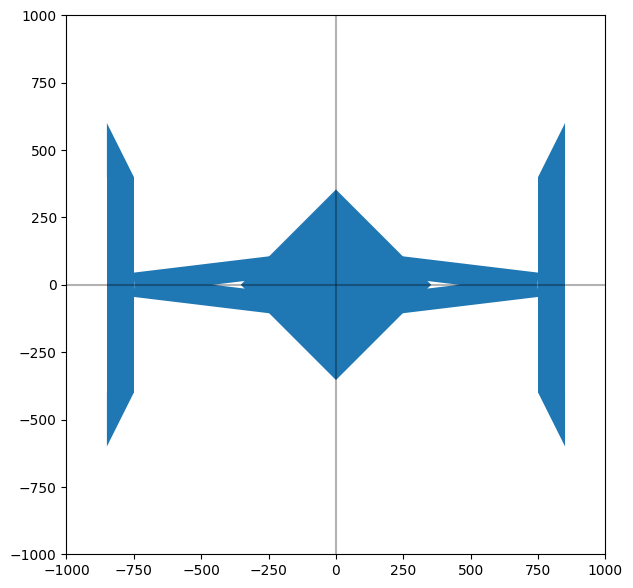

In [11]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()